# 01 - Data Preprocessing: India Hospital Readmission (five linked tables)
Run this notebook **before** the modelling notebook (`hospital_readmission_v2.ipynb`). It inspects the five CSV files, checks quality
(missing values, duplicates, key integrity, impossible values, outliers), merges the tables, applies the documented cleaning rules and
exports the model-ready table. Every number printed here can be quoted in the paper.

## 1. Setup and data location

In [1]:
import os, sys, json, warnings
warnings.filterwarnings("ignore")
IN_COLAB = 'google.colab' in sys.modules
DATA_DIR = "All Data"   # folder with admissions.csv, patients.csv, diagnoses.csv, billing.csv, hospitals.csv
if IN_COLAB and not os.path.isdir(DATA_DIR):
    from google.colab import drive
    drive.mount('/content/drive')
    DATA_DIR = "/content/drive/MyDrive/All Data"   # <-- change if your Drive folder is elsewhere
OUT = "outputs_pre"; os.makedirs(f"{OUT}/figures", exist_ok=True); os.makedirs("src", exist_ok=True)
print("Data dir:", DATA_DIR); print(sorted(os.listdir(DATA_DIR)))

Data dir: All Data
['admissions.csv', 'billing.csv', 'diagnoses.csv', 'hospitals.csv', 'patients.csv']


In [2]:
%%writefile src/preprocessing.py
"""Load the five relational tables, merge them and prepare model-ready matrices."""
import numpy as np
import pandas as pd
from sklearn.model_selection import GroupShuffleSplit
from sklearn.preprocessing import StandardScaler

SEED = 42
TARGET = "readmitted_30d"
LEAK_COLS = ["readmitted_7d"]  # 7-day outcome is a sub-event of the target


def load_tables(data_dir):
    # keep_default_na=False: the string "None" in insurance_type means uninsured, not missing
    t = {n: pd.read_csv(f"{data_dir}/{n}.csv", keep_default_na=False, na_values=[""])
         for n in ["admissions", "patients", "diagnoses", "billing", "hospitals"]}
    return t


def quality_report(t):
    rep = {}
    for n, d in t.items():
        rep[n] = dict(rows=len(d), cols=d.shape[1], missing=int(d.isna().sum().sum()),
                      duplicates=int(d.duplicated().sum()))
    return rep


def build_dataset(t, drop_expired=True):
    a, p, d, b, h = (t[k].copy() for k in ["admissions", "patients", "diagnoses", "billing", "hospitals"])
    a = a.drop_duplicates("admission_id")
    prim = d[d.diag_rank == 1].drop_duplicates("admission_id")[["admission_id", "diag_category"]]
    ndx = d.groupby("admission_id").size().rename("n_diagnoses").reset_index()
    h = h[["hospital_id", "tier", "beds", "teaching"]].rename(columns={"tier": "hospital_tier"})
    p = p.rename(columns={"state": "patient_state"})
    df = (a.merge(p, on="patient_id", how="left").merge(h, on="hospital_id", how="left")
           .merge(b.drop(columns="bill_id"), on="admission_id", how="left")
           .merge(prim, on="admission_id", how="left").merge(ndx, on="admission_id", how="left"))
    n0 = len(df)
    if drop_expired:  # patients who died cannot be readmitted
        df = df[df.discharge_type != "Expired"]
    df["admit_date"] = pd.to_datetime(df["admit_date"])
    df["admit_year"] = df.admit_date.dt.year
    df["admit_month"] = df.admit_date.dt.month
    df["cost_per_day"] = df.total_cost_inr / df.los_days.clip(lower=1)
    df["oop_share"] = df.out_of_pocket_inr / df.total_cost_inr.clip(lower=1)
    df["teaching"] = df["teaching"].astype(int)
    df["bpl_card"] = df["bpl_card"].astype(int)
    df["diag_category"] = df["diag_category"].fillna("Unknown")
    df["n_diagnoses"] = df["n_diagnoses"].fillna(1)
    df.attrs["dropped_expired"] = n0 - len(df)
    return df.reset_index(drop=True)


ID_COLS = ["admission_id", "patient_id", "hospital_id", "admit_date", "discharge_date"]
CAT_COLS = ["admit_type", "ward_type", "discharge_type", "gender", "patient_state", "insurance_type",
            "hospital_tier", "cost_category", "diag_category"]


def feature_frame(df):
    """One-hot encode categoricals; median-impute numerics. Returns X (DataFrame), y."""
    X = df.drop(columns=ID_COLS + [TARGET] + LEAK_COLS)
    num = [c for c in X.columns if c not in CAT_COLS]
    X[num] = X[num].fillna(X[num].median())
    X[CAT_COLS] = X[CAT_COLS].fillna("Unknown")
    X = pd.get_dummies(X, columns=CAT_COLS, dtype=float)
    return X, df[TARGET].values, num


def split_by_patient(df, seed=SEED, test=0.15, val=0.15):
    """Patient-grouped stratification-free split so one patient never spans two sets."""
    g = df.patient_id.values
    gss = GroupShuffleSplit(n_splits=1, test_size=test, random_state=seed)
    tv, te = next(gss.split(df, groups=g))
    gss2 = GroupShuffleSplit(n_splits=1, test_size=val / (1 - test), random_state=seed)
    tr, va = next(gss2.split(df.iloc[tv], groups=g[tv]))
    return tv[tr], tv[va], te


def scale(X_tr, X_va, X_te, num_cols):
    sc = StandardScaler().fit(X_tr[num_cols])
    out = []
    for X in (X_tr, X_va, X_te):
        Z = X.copy()
        Z[num_cols] = sc.transform(X[num_cols])
        out.append(Z)
    return out

Overwriting src/preprocessing.py


## 2. Load the raw tables and inspect structure

In [3]:
sys.path.insert(0, "src")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import preprocessing as P
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
REPORT = {}
# keep_default_na=False: the text "None" in insurance_type means 'uninsured' and must NOT be read as a missing value
t = P.load_tables(DATA_DIR)
raw_default = pd.read_csv(f"{DATA_DIR}/patients.csv")   # what plain pandas would do
REPORT["insurance_None_misread_as_NaN_by_default_pandas"] = int(raw_default.insurance_type.isna().sum())
print("Rows that plain pandas would wrongly treat as missing insurance:", REPORT["insurance_None_misread_as_NaN_by_default_pandas"])
rows = []
for n, d in t.items():
    rows.append(dict(table=n, rows=len(d), columns=d.shape[1], memory_MB=round(d.memory_usage(deep=True).sum() / 1e6, 1)))
display(pd.DataFrame(rows)); REPORT["tables"] = rows
for n, d in t.items():
    print(f"\n--- {n} ---"); display(pd.DataFrame({"dtype": d.dtypes.astype(str), "n_unique": d.nunique(), "example": d.iloc[0]}))

Rows that plain pandas would wrongly treat as missing insurance: 24715


,table,rows,columns,memory_MB
0,admissions,120000,17,81.3
1,patients,86400,8,26.4
2,diagnoses,271341,6,110.7
3,billing,120000,6,32.8
4,hospitals,33,6,0.0



--- admissions ---


,dtype,n_unique,example
admission_id,object,120000,bcb311d6-0808-498f-8ae1-11abe1fbc08e
patient_id,object,64873,6960d399-8398-4db4-9a90-0b329b81bc2b
admit_date,object,3652,2024-01-23
discharge_date,object,3677,2024-01-27
los_days,int64,65,4
admit_type,object,3,Elective
ward_type,object,4,General
hospital_id,object,33,b22e7b51-2ea6-4611-a8e5-d3d24ec779d8
discharge_type,object,4,Recovered
num_procedures,int64,15,0



--- patients ---


,dtype,n_unique,example
patient_id,object,86400,2b179f89-9af7-45cf-86b4-3e01a47a3b7b
age,int64,96,36
gender,object,3,F
state,object,15,Telangana
bpl_card,bool,2,False
insurance_type,object,4,Private
comorbidity_count,int64,9,0
prev_admissions,int64,10,0


... (2 outputs left out)


--- billing ---


,dtype,n_unique,example
bill_id,object,120000,68e19242-4126-4a7a-afa2-9e6035cdcffa
admission_id,object,120000,bcb311d6-0808-498f-8ae1-11abe1fbc08e
total_cost_inr,int64,76298,18492
govt_subsidy_inr,int64,56756,16630
out_of_pocket_inr,int64,51467,1862
cost_category,object,4,Lab



--- hospitals ---


,dtype,n_unique,example
hospital_id,object,33,df0f948a-2202-459a-ba6f-7ffd7dedcc18
name,object,26,Government General Hospital Maharashtra
state,object,15,Maharashtra
tier,object,3,tier2
beds,int64,33,314
teaching,bool,2,True


## 3. Missing values

In [4]:
miss = {n: d.isna().sum() for n, d in t.items()}
tab = pd.DataFrame({n: m.sum() for n, m in miss.items()}, index=["missing_cells"]).T
tab["blank_strings"] = [int(sum((d[c].astype(str).str.strip() == "").sum() for c in d.columns if d[c].dtype == object)) for d in t.values()]
display(tab); REPORT["missing_cells"] = {n: int(m.sum()) for n, m in miss.items()}
print("Textual placeholders that look like missing values but are real categories:")
for n, d in t.items():
    for c in d.select_dtypes("object").columns:
        v = d[c].astype(str).str.lower().isin(["none", "nan", "null", "na", "n/a", "unknown", "-"])
        if v.any(): print(f"  {n}.{c}: {int(v.sum())} rows -> {sorted(d.loc[v, c].unique())}")

,missing_cells,blank_strings
admissions,0,0
patients,0,0
diagnoses,0,0
billing,0,0
hospitals,0,0


Textual placeholders that look like missing values but are real categories:


  patients.insurance_type: 24715 rows -> ['None']


## 4. Duplicates and key integrity

In [5]:
dup = {n: int(d.duplicated().sum()) for n, d in t.items()}; REPORT["full_row_duplicates"] = dup
print("Fully duplicated rows:", dup)
a, p, dg, b, h = (t[k] for k in ["admissions", "patients", "diagnoses", "billing", "hospitals"])
keys = {"admissions.admission_id": a.admission_id, "patients.patient_id": p.patient_id, "hospitals.hospital_id": h.hospital_id,
        "billing.bill_id": b.bill_id, "billing.admission_id": b.admission_id, "diagnoses.diag_id": dg.diag_id}
REPORT["key_uniqueness"] = {k: bool(v.is_unique) for k, v in keys.items()}; print("Unique keys:", REPORT["key_uniqueness"])
integ = {
 "admissions.patient_id not in patients": int((~a.patient_id.isin(p.patient_id)).sum()),
 "admissions.hospital_id not in hospitals": int((~a.hospital_id.isin(h.hospital_id)).sum()),
 "billing.admission_id not in admissions": int((~b.admission_id.isin(a.admission_id)).sum()),
 "admissions without a bill": int((~a.admission_id.isin(b.admission_id)).sum()),
 "diagnoses.admission_id not in admissions": int((~dg.admission_id.isin(a.admission_id)).sum()),
 "admissions without any diagnosis": int((~a.admission_id.isin(dg.admission_id)).sum()),
 "admissions without a rank-1 diagnosis": int((~a.admission_id.isin(dg.loc[dg.diag_rank == 1, "admission_id"])).sum()),
 "duplicate (admission_id, diag_rank) pairs": int(dg.duplicated(["admission_id", "diag_rank"]).sum()),
}
REPORT["referential_integrity"] = integ; display(pd.Series(integ, name="violations"))
print("Admissions per patient:", a.groupby("patient_id").size().describe().round(2).to_dict())
REPORT["patients_with_repeat_admissions"] = int((a.groupby("patient_id").size() > 1).sum())
print("Patients with more than one admission:", REPORT["patients_with_repeat_admissions"], "-> a patient-grouped split is required")

Fully duplicated rows: {'admissions': 0, 'patients': 0, 'diagnoses': 0, 'billing': 0, 'hospitals': 0}


Unique keys: {'admissions.admission_id': True, 'patients.patient_id': True, 'hospitals.hospital_id': True, 'billing.bill_id': True, 'billing.admission_id': True, 'diagnoses.diag_id': True}


admissions.patient_id not in patients        0
admissions.hospital_id not in hospitals      0
billing.admission_id not in admissions       0
admissions without a bill                    0
diagnoses.admission_id not in admissions     0
admissions without any diagnosis             0
admissions without a rank-1 diagnosis        0
duplicate (admission_id, diag_rank) pairs    0
Name: violations, dtype: int64

Admissions per patient: {'count': 64873.0, 'mean': 1.85, 'std': 1.0, 'min': 1.0, '25%': 1.0, '50%': 2.0, '75%': 2.0, 'max': 10.0}


Patients with more than one admission: 34978 -> a patient-grouped split is required


## 5. Value validity checks

In [6]:
ad = a.copy(); ad["admit_date"] = pd.to_datetime(ad.admit_date); ad["discharge_date"] = pd.to_datetime(ad.discharge_date)
chk = {
 "discharge before admission": int((ad.discharge_date < ad.admit_date).sum()),
 "los_days != date difference": int((ad.los_days != (ad.discharge_date - ad.admit_date).dt.days).sum()),
 "los_days < 1": int((ad.los_days < 1).sum()),
 "negative num_procedures": int((ad.num_procedures < 0).sum()),
 "charlson outside 0-6": int((~ad.charlson_index.between(0, 6)).sum()),
 "systolic_bp outside 60-250": int((~ad.systolic_bp.between(60, 250)).sum()),
 "haemoglobin outside 3-20": int((~ad.haemoglobin.between(3, 20)).sum()),
 "creatinine outside 0.2-20": int((~ad.creatinine.between(0.2, 20)).sum()),
 "hba1c outside 3-20": int((~ad.hba1c.between(3, 20)).sum()),
 "readmitted_7d = 1 but readmitted_30d = 0": int(((ad.readmitted_7d == 1) & (ad.readmitted_30d == 0)).sum()),
 "age outside 0-120": int((~p.age.between(0, 120)).sum()),
 "prev_admissions < 0": int((p.prev_admissions < 0).sum()),
 "billing: total != subsidy + out_of_pocket": int((b.total_cost_inr != b.govt_subsidy_inr + b.out_of_pocket_inr).sum()),
 "billing: negative amounts": int(((b[["total_cost_inr", "govt_subsidy_inr", "out_of_pocket_inr"]] < 0).any(axis=1)).sum()),
}
REPORT["validity_violations"] = chk; display(pd.Series(chk, name="violations"))
print("Admission date range:", ad.admit_date.min().date(), "to", ad.admit_date.max().date())
for c in ["admit_type", "ward_type", "discharge_type"]: print(c, a[c].value_counts().to_dict())
for c in ["gender", "insurance_type"]: print(c, p[c].value_counts().to_dict())
print("hospital tier:", h.tier.value_counts().to_dict(), "| states:", h.state.nunique())

discharge before admission                   0
los_days != date difference                  0
los_days < 1                                 0
negative num_procedures                      0
charlson outside 0-6                         0
systolic_bp outside 60-250                   0
haemoglobin outside 3-20                     0
creatinine outside 0.2-20                    0
hba1c outside 3-20                           0
readmitted_7d = 1 but readmitted_30d = 0     0
age outside 0-120                            0
prev_admissions < 0                          0
billing: total != subsidy + out_of_pocket    0
billing: negative amounts                    0
Name: violations, dtype: int64

Admission date range: 2015-01-01 to 2024-12-30
admit_type {'Emergency': 66540, 'Elective': 37853, 'OPD': 15607}
ward_type {'General': 76768, 'ICU': 20833, 'HDU': 15907, 'NICU': 6492}
discharge_type {'Recovered': 87420, 'LAMA': 15429, 'Referred': 9738, 'Expired': 7413}
gender {'M': 44190, 'F': 41361, 'Other': 849}
insurance_type {'Ayushman': 25967, 'None': 24715, 'Private': 21372, 'ESI': 14346}
hospital tier: {'tier2': 15, 'tier3': 10, 'tier1': 8} | states: 15


## 6. Outliers (reported, not removed)
Values are inspected with the 1.5 x IQR rule. They are clinically plausible (e.g. long stays, high creatinine), so they are **kept**; tree models and scaling are robust enough for this.

In [7]:
num = ["los_days", "num_procedures", "charlson_index", "hba1c", "creatinine", "haemoglobin", "systolic_bp"]
rows = []
for c in num:
    q1, q3 = a[c].quantile([.25, .75]); i = q3 - q1; lo, hi = q1 - 1.5 * i, q3 + 1.5 * i
    rows.append(dict(column=c, min=a[c].min(), median=a[c].median(), max=a[c].max(), outside_IQR_rule=int(((a[c] < lo) | (a[c] > hi)).sum()), pct=round(100 * ((a[c] < lo) | (a[c] > hi)).mean(), 2)))
display(pd.DataFrame(rows)); REPORT["outliers_IQR"] = rows

,column,min,median,max,outside_IQR_rule,pct
0,los_days,1.0,5.00,90.0,5812,4.84
1,num_procedures,0.0,1.00,15.0,2640,2.20
2,charlson_index,0.0,2.00,6.0,0,0.00
3,hba1c,4.0,5.70,14.3,9179,7.65
4,creatinine,0.4,0.91,15.0,5925,4.94
5,haemoglobin,4.0,11.90,18.0,889,0.74
6,systolic_bp,70.0,134.00,220.0,772,0.64


## 7. Target variable and the in-hospital-death rule

In [8]:
REPORT["target_all_admissions"] = dict(n=len(a), readmitted=int(a.readmitted_30d.sum()), rate=float(a.readmitted_30d.mean()))
print("30-day readmission, all admissions:", REPORT["target_all_admissions"])
dd = a.groupby("discharge_type").readmitted_30d.agg(["count", "sum", "mean"]).round(4); display(dd)
REPORT["readmission_by_discharge_type"] = {k: dict(n=int(v["count"]), readmitted=int(v["sum"]), rate=float(v["mean"])) for k, v in dd.iterrows()}
print("RULE: discharge_type == 'Expired' (in-hospital death) -> cannot be readmitted (rate above is 0) -> excluded from modelling.")

30-day readmission, all admissions: {'n': 120000, 'readmitted': 14210, 'rate': 0.11841666666666667}


,count,sum,mean
discharge_type,,,
Expired,7413,0,0.0000
LAMA,15429,2747,0.1780
Recovered,87420,10302,0.1178
Referred,9738,1161,0.1192


RULE: discharge_type == 'Expired' (in-hospital death) -> cannot be readmitted (rate above is 0) -> excluded from modelling.


## 8. Merge, clean and engineer features (the exact function the modelling notebook uses)

In [9]:
df = P.build_dataset(t)                       # joins, rank-1 diagnosis, n_diagnoses, drops deaths, date/billing features
X, y, num_cols = P.feature_frame(df)          # median imputation + one-hot encoding (used for the models)
REPORT["after_cleaning"] = dict(rows=len(df), patients=int(df.patient_id.nunique()), readmitted=int(df.readmitted_30d.sum()),
                                rate=float(df.readmitted_30d.mean()), dropped_expired=int(df.attrs["dropped_expired"]),
                                model_columns=int(X.shape[1]), numeric_columns=len(num_cols), categorical_raw=len(P.CAT_COLS))
print(REPORT["after_cleaning"])
assert df.admission_id.is_unique and not X.isna().any().any() and set(np.unique(y)) <= {0, 1}
assert not any(c in X.columns for c in P.LEAK_COLS + [P.TARGET]), "leakage column present"
print("Derived columns added:", [c for c in df.columns if c not in a.columns and c not in p.columns and c not in h.columns and c not in b.columns][:10])
print("Categorical columns one-hot encoded:", P.CAT_COLS)
display(df.drop(columns=P.ID_COLS).describe().T.round(2).head(30))

{'rows': 112587, 'patients': 62923, 'readmitted': 14210, 'rate': 0.1262135059998046, 'dropped_expired': 7413, 'model_columns': 71, 'numeric_columns': 21, 'categorical_raw': 9}
Derived columns added: ['patient_state', 'hospital_tier', 'diag_category', 'n_diagnoses', 'admit_year', 'admit_month', 'cost_per_day', 'oop_share']
Categorical columns one-hot encoded: ['admit_type', 'ward_type', 'discharge_type', 'gender', 'patient_state', 'insurance_type', 'hospital_tier', 'cost_category', 'diag_category']


,count,mean,std,min,25%,50%,75%,max
los_days,112587.0,6.88,5.74,1.0,3.00,5.00,9.00,90.00
num_procedures,112587.0,1.53,1.55,0.0,0.00,1.00,2.00,15.00
charlson_index,112587.0,1.90,1.61,0.0,0.00,2.00,3.00,6.00
hba1c,112587.0,5.87,1.06,4.0,5.30,5.70,6.10,14.30
creatinine,112587.0,1.07,0.90,0.4,0.77,0.91,1.10,15.00
haemoglobin,112587.0,11.83,2.17,4.0,10.40,11.90,13.30,18.00
systolic_bp,112587.0,134.66,20.76,70.0,120.00,134.00,148.00,220.00
readmitted_30d,112587.0,0.13,0.33,0.0,0.00,0.00,0.00,1.00
readmitted_7d,112587.0,0.01,0.09,0.0,0.00,0.00,0.00,1.00
age,112587.0,48.13,21.64,0.0,36.00,51.00,63.00,95.00


## 9. Figures

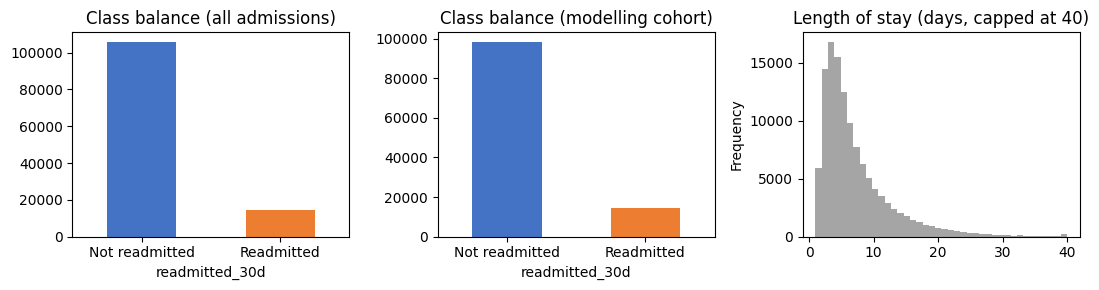

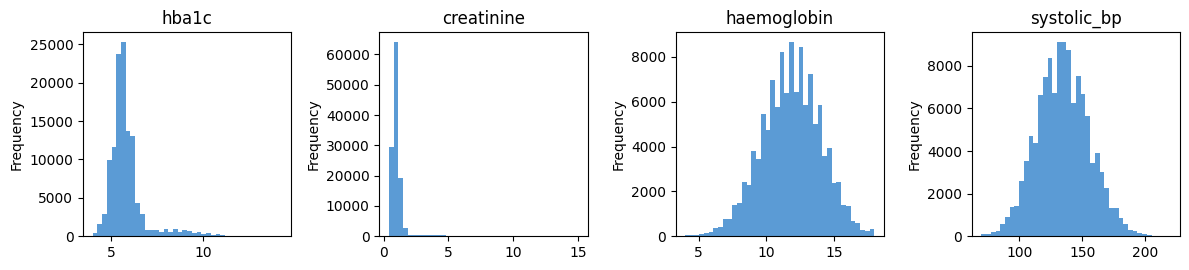

In [10]:
fig, ax = plt.subplots(1, 3, figsize=(11, 3))
a.readmitted_30d.map({0: "Not readmitted", 1: "Readmitted"}).value_counts().plot.bar(ax=ax[0], color=["#4472C4", "#ED7D31"], rot=0); ax[0].set_title("Class balance (all admissions)")
df.readmitted_30d.map({0: "Not readmitted", 1: "Readmitted"}).value_counts().plot.bar(ax=ax[1], color=["#4472C4", "#ED7D31"], rot=0); ax[1].set_title("Class balance (modelling cohort)")
a.los_days.clip(upper=40).plot.hist(bins=40, ax=ax[2], color="#A5A5A5"); ax[2].set_title("Length of stay (days, capped at 40)")
plt.tight_layout(); plt.savefig(f"{OUT}/figures/pre_class_and_los.png", dpi=200); plt.show()
fig, axs = plt.subplots(1, 4, figsize=(12, 2.8))
for ax_, c in zip(axs, ["hba1c", "creatinine", "haemoglobin", "systolic_bp"]): a[c].plot.hist(bins=40, ax=ax_, color="#5B9BD5"); ax_.set_title(c)
plt.tight_layout(); plt.savefig(f"{OUT}/figures/pre_lab_distributions.png", dpi=200); plt.show()

## 10. Export the cleaned table and the preprocessing report

In [11]:
clean_cols = [c for c in df.columns if c not in ["patient_id", "hospital_id", "admission_id", "admit_date", "discharge_date"]]
df.to_csv(f"{OUT}/readmission_clean_merged.csv", index=False)             # keeps IDs (needed for the patient-grouped split)
pd.DataFrame({"column": df.columns, "dtype": df.dtypes.astype(str).values, "n_unique": df.nunique().values}).to_csv(f"{OUT}/data_dictionary.csv", index=False)
json.dump(REPORT, open(f"{OUT}/preprocessing_report.json", "w"), indent=2, default=lambda o: o.item() if hasattr(o, "item") else str(o))
print("Saved:", sorted(os.listdir(OUT)))

Saved: ['data_dictionary.csv', 'figures', 'preprocessing_report.json', 'readmission_clean_merged.csv']


## 11. Summary for the paper (take ONE screenshot of this cell's output)

In [12]:
print("=== TABLES ===");  print(pd.DataFrame(REPORT["tables"]).to_string(index=False))
print("\nmissing cells:", REPORT["missing_cells"], "| 'None' insurance misread as NaN by default pandas:", REPORT["insurance_None_misread_as_NaN_by_default_pandas"])
print("full-row duplicates:", REPORT["full_row_duplicates"]); print("keys unique:", all(REPORT["key_uniqueness"].values()))
print("integrity violations:", sum(REPORT["referential_integrity"].values()), "| validity violations:", {k: v for k, v in REPORT["validity_violations"].items() if v})
print("repeat-admission patients:", REPORT["patients_with_repeat_admissions"])
print("all admissions:", REPORT["target_all_admissions"]); print("after cleaning:", REPORT["after_cleaning"])

=== TABLES ===
     table   rows  columns  memory_MB
admissions 120000       17       81.3
  patients  86400        8       26.4
 diagnoses 271341        6      110.7
   billing 120000        6       32.8
 hospitals     33        6        0.0

missing cells: {'admissions': 0, 'patients': 0, 'diagnoses': 0, 'billing': 0, 'hospitals': 0} | 'None' insurance misread as NaN by default pandas: 24715
full-row duplicates: {'admissions': 0, 'patients': 0, 'diagnoses': 0, 'billing': 0, 'hospitals': 0}
keys unique: True
integrity violations: 0 | validity violations: {}
repeat-admission patients: 34978
all admissions: {'n': 120000, 'readmitted': 14210, 'rate': 0.11841666666666667}
after cleaning: {'rows': 112587, 'patients': 62923, 'readmitted': 14210, 'rate': 0.1262135059998046, 'dropped_expired': 7413, 'model_columns': 71, 'numeric_columns': 21, 'categorical_raw': 9}


## 12. Download (Colab only)

In [13]:
import shutil
if IN_COLAB:
    shutil.make_archive("outputs_pre_download", "zip", OUT)
    from google.colab import files
    files.download("outputs_pre_download.zip")